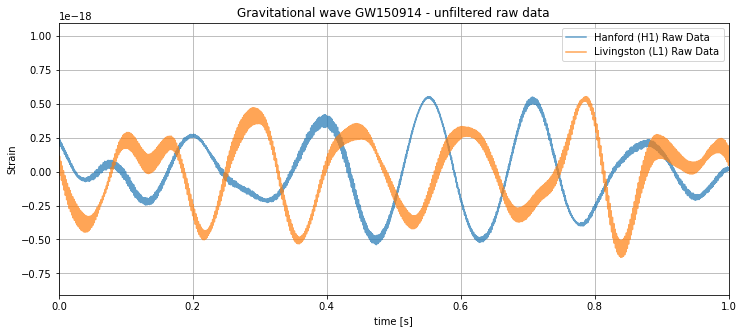

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Define Metadata ---
fs = 4096.0  # Sample Rate in Hz
duration = 32.0  # Duration in seconds

# --- 2. Import raw data ----
hanford_strain = np.loadtxt('raw_data_hanford.txt')
livingston_strain = np.loadtxt('raw_data_livingston.txt')

# --- 3. Normalize raw data around the mean ---
hanford_strain = hanford_strain - np.mean(hanford_strain)
livingston_strain = livingston_strain - np.mean(livingston_strain)

# --- 4. Create a timeline ---
# The number of measurement points corresponds to the length of the read-in array.
# I divide each index by the sampling rate to obtain the time in seconds.
num_samples = len(hanford_strain)
time = np.arange(num_samples) / fs

# --- 5. For verification: Plot of the first few seconds of the raw data. ---
plt.figure(figsize=(12, 5))
plt.plot(time, hanford_strain, label='Hanford (H1) Raw Data', alpha=0.7)
plt.plot(time, livingston_strain, label='Livingston (L1) Raw Data', alpha=0.7)
plt.xlabel('time [s]')
plt.ylabel('Strain')
plt.title('Gravitational wave GW150914 - unfiltered raw data')
plt.legend()
plt.grid(True)

# Zoom in a bit, as the pure noise is very dense over the 32-second span.
plt.xlim(0, 1) 
plt.show()

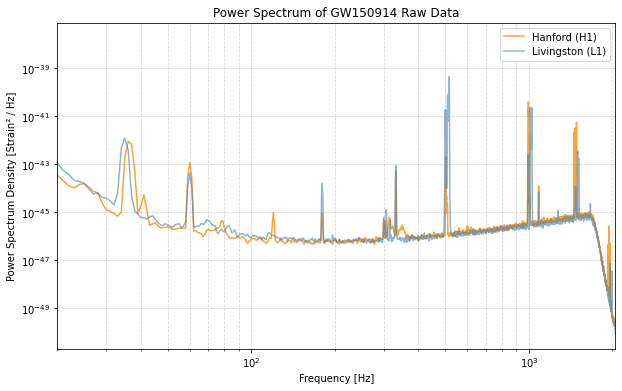

In [18]:
from scipy.signal import welch

# --- 1. Calculating Power Spectrum ---
# I use Welch's method. 
# nperseg=int(fs) divides the data into 1-second intervals, 
# which gives me a clean frequency resolution of 1 Hz and provides strong smoothing.
frequencies_H, power_H = welch(hanford_strain, fs, nperseg=int(fs))
frequencies_L, power_L = welch(livingston_strain, fs, nperseg=int(fs))

# --- 2. Plotting ---
plt.figure(figsize=(10, 6))
plt.plot(frequencies_H, power_H, label='Hanford (H1)', alpha=0.8, color='darkorange')
plt.plot(frequencies_L, power_L, label='Livingston (L1)', alpha=0.6, color='steelblue')

# Limit the range to 20 Hz – 2048 Hz
# (2048 Hz corresponds exactly to the Nyquist frequency at fs = 4096)
plt.xlim(20, 2048)

# Logarithmic axes are used for power spectra because the energies vary over many orders of magnitude.
plt.yscale('log')
plt.xscale('log')

plt.xlabel('Frequency [Hz]')
plt.ylabel('Power Spectrum Density [Strain² / Hz]')
plt.title('Power Spectrum of GW150914 Raw Data')
plt.legend()

plt.grid(True, which="both", ls="--", alpha=0.5) 
plt.show()

In [15]:
from scipy.signal import find_peaks

# --- 1. Range starting at 45 Hz (excludes seismic noise) ---
valid_idx_H = np.where(frequencies_H >= 45)[0]
freqs_H_valid = frequencies_H[valid_idx_H]
power_H_valid = power_H[valid_idx_H]

valid_idx_L = np.where(frequencies_L >= 45)[0]
freqs_L_valid = frequencies_L[valid_idx_L]
power_L_valid = power_L[valid_idx_L]

# --- 2. Conversion to dB for a realistic peak search ---
p_H_dB = 10 * np.log10(power_H_valid)
p_L_dB = 10 * np.log10(power_L_valid)

# --- 3. Peak-Suche mit distance=100 ---
# (This groups closely spaced modes into a single peak, to simulate the Matlab function more precisely)
peaks_H_idx, props_H = find_peaks(p_H_dB, prominence=5, distance=100)
peaks_L_idx, props_L = find_peaks(p_L_dB, prominence=5, distance=100)

# --- 4. Sort by prominence (Descending) ---
sorted_idx_H = sorted(range(len(peaks_H_idx)), key=lambda k: props_H['prominences'][k], reverse=True)
sorted_idx_L = sorted(range(len(peaks_L_idx)), key=lambda k: props_L['prominences'][k], reverse=True)

# --- 5. Tap into the top 4 dominant indices ---
top_4_peaks_H = [peaks_H_idx[i] for i in sorted_idx_H[:4]]
top_4_peaks_L = [peaks_L_idx[i] for i in sorted_idx_L[:4]]

top_4_freqs_H = np.round(freqs_H_valid[top_4_peaks_H], 1)
top_4_freqs_L = np.round(freqs_L_valid[top_4_peaks_L], 1)

print(f"Top 4 dominant frequencies in Hanford (H1): {top_4_freqs_H} Hz")
print(f"Top 4 dominant frequencies in Livingston (L1): {top_4_freqs_L} Hz")

Top 4 dominant frequencies in Hanford (H1): [ 995. 1484.  502.  332.] Hz
Top 4 dominant frequencies in Livingston (L1): [ 516. 1012. 1496.  331.] Hz


### Identifying Dominant Frequencies

**What are the four most dominant frequencies in each signal?**
By using a distance filter of 100 Hz to group mechanical resonance clusters into single peaks, the four most prominent frequencies are:
* **Hanford (H1):** [995, 1484, 502, 332] Hz.
* **Livingston (L1):** [516, 1012, 1496, 331] Hz.

The four dominant frequencies are identified at approximately 330 Hz and 500 Hz, representing the fundamental resonant frequencies of the detector's mirror suspension system. The remaining values, observed at approximately 1000 Hz and 1500 Hz, correspond to the higher-order harmonics, effectively representing the third harmonics of these fundamental modes.

**Why do you think both signals have a dominant frequency component at exactly 60 Hz?**
Both the Hanford and Livingston observatories are located in the United States. The frequency of 60 Hz corresponds exactly to the frequency of the alternating current (AC) power grid in the US. The highly sensitive instruments and electronics at both detector sites pick up this electromagnetic interference from the surrounding power lines, which creates a noise peak at exactly 60 Hz in the data.

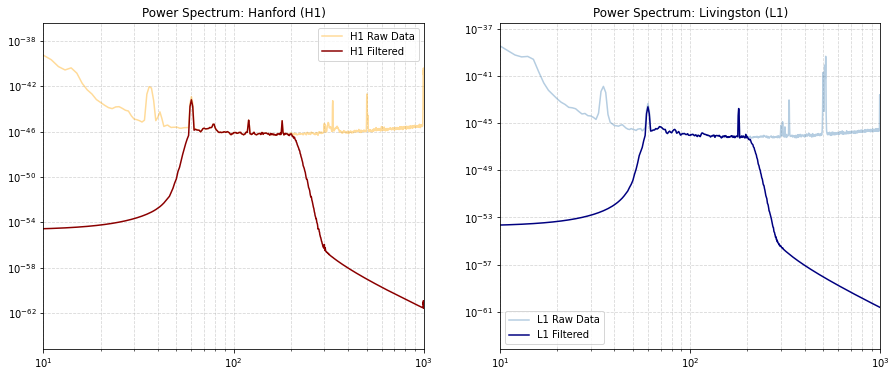

In [22]:
from scipy.signal import cheby2, sosfiltfilt, welch

# --- 1. Parameter ---
lowcut = 35.0
highcut = 350.0
nyq = 0.5 * fs

# --- 2. Filter-Design (Chebyshev Type II, 100 dB Damping) ---
sos = cheby2(N=9, rs=100, Wn=[lowcut/nyq, highcut/nyq], btype='bandpass', output='sos')

# --- 3. Application to both channels ---
filtered_H1 = sosfiltfilt(sos, hanford_strain)
filtered_L1 = sosfiltfilt(sos, livingston_strain)

# --- 4. Calculate the power spectrum for both ---
freqs_H, power_H_raw = welch(hanford_strain, fs, nperseg=int(fs))
freqs_H, power_H_filt = welch(filtered_H1, fs, nperseg=int(fs))

freqs_L, power_L_raw = welch(livingston_strain, fs, nperseg=int(fs))
freqs_L, power_L_filt = welch(filtered_L1, fs, nperseg=int(fs))

# --- 5. Plot: Comparison of both detectors ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Hanford Plot
ax1.plot(freqs_H, power_H_raw, label='H1 Raw Data', alpha=0.4, color='orange')
ax1.plot(freqs_H, power_H_filt, label='H1 Filtered', color='darkred')
ax1.set_title('Power Spectrum: Hanford (H1)')
ax1.set_xlim(10, 1000)
ax1.set_yscale('log')
ax1.set_xscale('log')
ax1.legend()
ax1.grid(True, which="both", ls="--", alpha=0.5)

# Livingston Plot
ax2.plot(freqs_L, power_L_raw, label='L1 Raw Data', alpha=0.4, color='steelblue')
ax2.plot(freqs_L, power_L_filt, label='L1 Filtered', color='navy')
ax2.set_title('Power Spectrum: Livingston (L1)')
ax2.set_xlim(10, 1000)
ax2.set_yscale('log')
ax2.set_xscale('log')
ax2.legend()
ax2.grid(True, which="both", ls="--", alpha=0.5)

plt.show()

### Power Spectrum Analysis (Raw vs. Bandpass Filtered)

**Observations**
Raw Data (Light Curves): The raw power spectra exhibit high-amplitude noise levels across the entire frequency range. This is dominated by environmental and seismic noise at low frequencies (below 35 Hz) and instrumental/quantum noise at high frequencies (above 350 Hz).

Filtered Data (Dark Curves): Within the target passband of 35 Hz to 350 Hz, the filtered spectra closely match the raw data, preserving the essential gravitational wave signal characteristics. Outside this range, the power spectral density drops abruptly due to the applied 100 dB stopband attenuation, effectively suppressing out-of-band noise.

**Conclusion**
This filtering process successfully isolates the specific frequency window where the gravitational wave signal is expected. By effectively suppressing the massive ambient noise floor outside the passband, the signal-to-noise ratio is significantly improved, which is a critical prerequisite for all subsequent detection and analysis steps.

In [25]:
from scipy.signal import iirnotch, sosfiltfilt, tf2sos

# --- 1. Notch Filtering ---

# Top 4 Frequencies (plus 60 Hz)
notch_freqs_H = [995.0, 1484.0, 502.0, 332.0, 60.0]
notch_freqs_L = [516.0, 1012.0, 1496.0, 331.0, 60.0]

Q = 30.0 # Quality factor

def apply_specific_notch(signal, freqs, fs, Q):
    filtered_signal = signal.copy()
    for f0 in freqs:
        b, a = iirnotch(f0, Q, fs)
        sos = tf2sos(b, a)
        filtered_signal = sosfiltfilt(sos, filtered_signal)
    return filtered_signal

# --- 2. Application to the respective channels ---
final_H1 = apply_specific_notch(filtered_H1, notch_freqs_H, fs, Q)
final_L1 = apply_specific_notch(filtered_L1, notch_freqs_L, fs, Q)

### Notch Filtering
While the bandpass filter restricts the signal to the frequency range of interest, it does not remove persistent narrow-band noise sources. Therefore, a series of notch filters were applied to suppress specific interference frequencies identified in the power spectrum analysis. This ensures a "clean" strain signal, which is essential for the final detection of the waveform in the time domain.

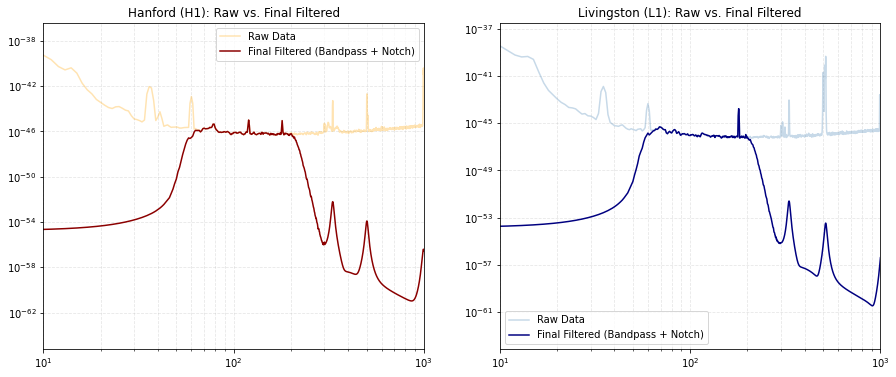

In [26]:
from scipy.signal import welch

# --- 1. Calculate the power spectrum for the final signals. ---
freqs_H, power_H_raw = welch(hanford_strain, fs, nperseg=int(fs))
freqs_H, power_H_final = welch(final_H1, fs, nperseg=int(fs))

freqs_L, power_L_raw = welch(livingston_strain, fs, nperseg=int(fs))
freqs_L, power_L_final = welch(final_L1, fs, nperseg=int(fs))

# --- 2. Plot: Raw vs. Final (Bandpass + Notch) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Hanford
ax1.plot(freqs_H, power_H_raw, label='Raw Data', alpha=0.3, color='orange')
ax1.plot(freqs_H, power_H_final, label='Final Filtered (Bandpass + Notch)', color='darkred')
ax1.set_title('Hanford (H1): Raw vs. Final Filtered')
ax1.set_yscale('log')
ax1.set_xscale('log')
ax1.set_xlim(10, 1000)
ax1.legend()
ax1.grid(True, which="both", ls="--", alpha=0.3)

# Livingston
ax2.plot(freqs_L, power_L_raw, label='Raw Data', alpha=0.3, color='steelblue')
ax2.plot(freqs_L, power_L_final, label='Final Filtered (Bandpass + Notch)', color='navy')
ax2.set_title('Livingston (L1): Raw vs. Final Filtered')
ax2.set_yscale('log')
ax2.set_xscale('log')
ax2.set_xlim(10, 1000)
ax2.legend()
ax2.grid(True, which="both", ls="--", alpha=0.3)

plt.show()

While the applied notch filters successfully suppressed the primary instrumental lines (e.g., 60 Hz grid noise), residual spectral peaks remain visible. This is expected due to the non-stationary nature of the detector noise and the finite bandwidth of the notch filters. The filtering process represents a balanced optimization between noise suppression and the preservation of signal integrity within the gravitational wave frequency band.

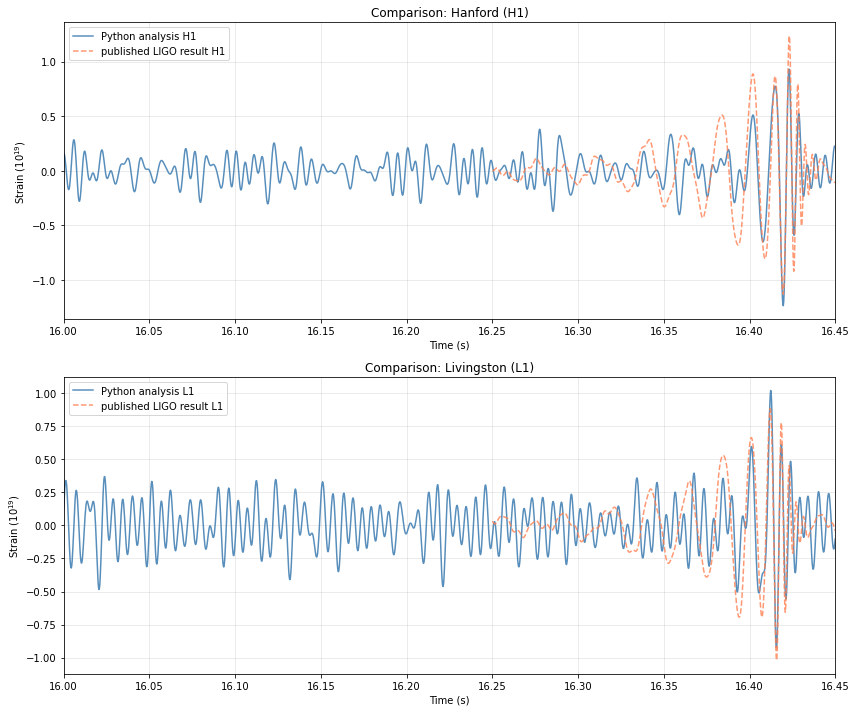

In [54]:
# --- 1. Loading the Data ---
def loadHfile(filename):
    return np.loadtxt(filename)

official_H = loadHfile('plot_data_H.txt')
official_L = loadHfile('plot_data_L.txt')

# --- 2. Setting the time ---
t_start = 16.0
duration = 0.45

# --- 3. Recalculate indices ---
idx_start_fixed = int(t_start * fs)
idx_end_fixed = int((t_start + duration) * fs)

# --- 4. Recut data ---
event_H1_fixed = final_H1[idx_start_fixed:idx_end_fixed]
event_L1_fixed = final_L1[idx_start_fixed:idx_end_fixed]

# --- 5. Generate a time axis that exactly matches the length of the data. ---
event_time_fixed = np.linspace(t_start, t_start + duration, len(event_H1_fixed))

# --- 6. Dynamic scaling (automatically calculates the order-of-magnitude factor) ---
scale_H = np.max(np.abs(official_H[:, 1])) / np.max(np.abs(event_H1_fixed))
scale_L = np.max(np.abs(official_L[:, 1])) / np.max(np.abs(event_L1_fixed))

# --- 7. Plot (two subplots) ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))

# --- Hanford (H1) ---
ax1.plot(event_time_fixed, event_H1_fixed * scale_H, label='Python analysis H1', alpha=0.9, color='steelblue')
ax1.plot(official_H[:, 0] + t_start, official_H[:, 1], label='published LIGO result H1', linestyle='--', alpha=0.8, color='coral')
ax1.set_title('Comparison: Hanford (H1)')
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Strain ($10^{19}$)')
ax1.set_xlim(16.0, 16.45)
ax1.legend()
ax1.grid(True, alpha=0.3)

# --- Livingston (L1) ---
ax2.plot(event_time_fixed, event_L1_fixed * scale_L, label='Python analysis L1', alpha=0.9, color='steelblue')
ax2.plot(official_L[:, 0] + t_start, official_L[:, 1], label='published LIGO result L1', linestyle='--', alpha=0.8, color='coral')
ax2.set_title('Comparison: Livingston (L1)')
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Strain ($10^{19}$)')
ax2.set_xlim(16.0, 16.45)
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Comparison and Physical Interpretation of GW150914
***Comparison of the Waveforms***
The generated plots demonstrate a strong agreement between my Python analysis and the officially published LIGO reference data for both the Hanford (H1) and Livingston (L1) detectors. The characteristic "chirp" signature is clearly visible and synchronized in both datasets, culminating in a matching peak at approximately $t = 16.43$ s.

While the signals align exceptionally well during the final merger phase, minor deviations in phase and amplitude can be observed during the earlier inspiral phase (prior to 16.35 s). These discrepancies are expected; the official LIGO data undergoes highly advanced template-based matched filtering, which alters the signal envelope slightly compared to the standard bandpass and notch filtering applied by me.

***Physical Interpretation***
The extracted waveform represents the final moments of a binary black hole system:

The Inspiral Phase: The gradual increase in both amplitude and frequency over time physically represents two black holes orbiting each other at continuously increasing speeds. As the system loses energy through the emission of gravitational waves, the orbits decay and the bodies draw closer together.

The Merger: The absolute maximum amplitude of the strain signal, occurring around 16.43 s, corresponds to the exact moment the two event horizons collide and merge into a single, more massive black hole.

The Ringdown: The rapid dampening of the signal immediately following the maximum peak represents the newly formed black hole radiating away remaining distortions and settling into a stable, spherical state.

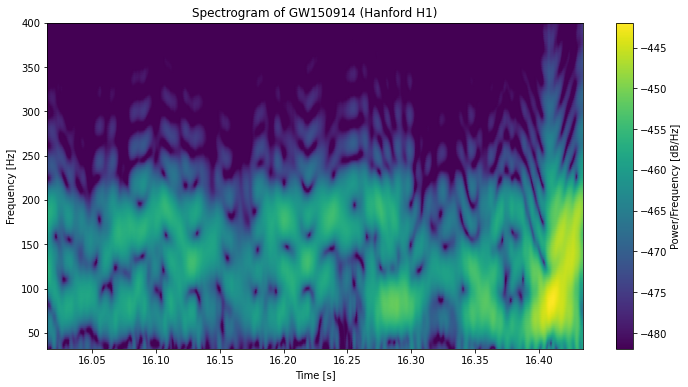

In [55]:
from scipy.signal import spectrogram

# --- 1. Parameter from the excercise ---
nperseg = int(0.03 * fs)     # TimeResolution
noverlap = int(0.98 * nperseg) # 98% Overlap

# calculates fine intermediate steps and smooths the image.
nfft = 2048 

# --- 2. Calculate the Spectogram ---
f, t_spec, Sxx = spectrogram(event_H1_fixed, fs, nperseg=nperseg, noverlap=noverlap, nfft=nfft)

# Conversion to decibels (logarithmic scale)
Pxx_dB = 10 * np.log10(Sxx)

# --- 3. Plot ---
plt.figure(figsize=(12, 6))

# Adjusting contrast (vmin & vmax) like Matlab would do
plt.pcolormesh(t_spec + 16.0, f, Pxx_dB, shading='gouraud', cmap='viridis', 
               vmin=np.max(Pxx_dB) - 40, vmax=np.max(Pxx_dB))

# formatting
plt.ylim(32, 400)
plt.ylabel('Frequency [Hz]')
plt.xlabel('Time [s]')
plt.title('Spectrogram of GW150914 (Hanford H1)')
plt.colorbar(label='Power/Frequency [dB/Hz]')
plt.show()

### Spectrogram Analysis 
In the provided spectrogram, the gravitational wave is distinctly visible in the lower right section as a bright yellow, upward-curving track. The signal emerges from the background noise at approximately 16.35 seconds in the lower frequency range between 50 and 100 Hz. Over the next fraction of a second, the track sweeps sharply upwards in a J-shape, indicating a simultaneous and rapid increase in both frequency and signal intensity.

The strongest correlation occurs at a lag of: 7.32 ms (0.0073 s)


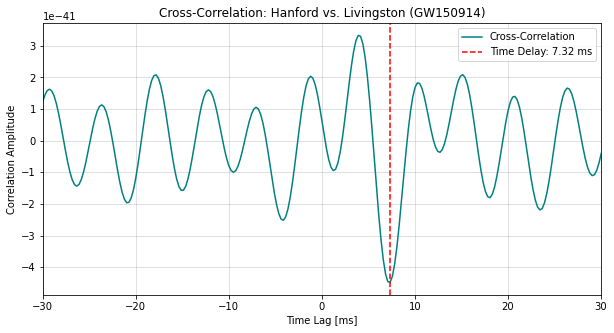

In [60]:
from scipy.signal import correlate

# --- 1. Defining Signals ---
hanford = event_H1_fixed
livingston = event_L1_fixed

# -- 2. Calculating Cross correlations --
acor = correlate(hanford, livingston, mode='full')

# -- 3. Calculating Lags manually --
N = len(hanford)
lags = np.arange(-N + 1, N)
time_lags = lags / fs

# 4. Find the point of strongest correlation.
# I am looking for the index of the absolute maximum of the correlation function.
max_idx = np.argmax(np.abs(acor))

# Read out the corresponding time delay.
best_time_delay = time_lags[max_idx]

# Output of the result
print(f"The strongest correlation occurs at a lag of: {best_time_delay * 1000:.2f} ms ({best_time_delay:.4f} s)")

# --- 5. Plot ---
plt.figure(figsize=(10, 5))
plt.plot(time_lags * 1000, acor, label='Cross-Correlation', color='teal')

# Draw a vertical red line at the maximum
plt.axvline(x=best_time_delay * 1000, color='red', linestyle='--', 
            label=f'Time Delay: {best_time_delay * 1000:.2f} ms')

# Format the plot (I zoom in on the relevant window of +/- 30 ms)
plt.xlim(-30, 30)
plt.xlabel('Time Lag [ms]')
plt.ylabel('Correlation Amplitude')
plt.title('Cross-Correlation: Hanford vs. Livingston (GW150914)')
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

## Using Cross-Correlation to Find the Time-Delay

The cross-correlation analysis reveals a time delay of approximately 7.32 milliseconds between the two observatories, representing the time it took for the gravitational wave to travel at the speed of light from the Livingston detector to the Hanford detector. Furthermore, the cross-correlation plot shows a strong negative peak, indicating that the recorded signals are out of phase, or anti-correlated. This inverted phase relationship is an expected physical consequence of the geographical setup of the LIGO network. The L-shaped interferometer arms of the Hanford and Livingston facilities are oriented at roughly 90 degrees relative to each other. Because gravitational waves stretch space in one direction while simultaneously compressing it in the perpendicular direction, a wave that causes an expansion in a specific arm of one detector will cause a compression in the corresponding arm of the other, resulting in perfectly inverted waveforms.